![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Embeddings and Semantic Search
*Data Science & Machine Learning - Week 7, Day 2*

## How to use this notebook

Yesterday ended with a problem. To TF-IDF, *I bought a new car* was three times more similar to *I bought a new banana* than to *I purchased a new automobile*, because TF-IDF only counts shared words. It has no idea that *car* and *automobile* mean the same thing.

Today you fix that with **embeddings**: every word, and then every sentence, becomes a list of a few hundred numbers in which texts with similar meanings end up close together. You will:

1. Explore **word vectors** (GloVe): find similar words, solve analogies, and compute cosine similarity by hand.
2. See where word vectors break: one meaning per word, unknown words, and sentences.
3. Use a **sentence embedding model** (`all-MiniLM-L6-v2`) that turns a whole sentence into one vector.
4. Build a **semantic search engine** from scratch on yesterday's forum posts and compare it with a TF-IDF search.
5. **Cluster** the posts and **classify** them with embeddings, and see why embeddings shine when you have few labels.

Semantic search is the *retrieval* half of the RAG systems you build on Day 5: before a language model can answer a question about your documents, something has to find the right documents. That something is what you build today.

The slides **1-NLP-Text-Processing-Embeddings** in this folder go with the notebook (there is a PDF copy too). Run the cells in order. The **Appendix** has extra material that is not part of the lesson.

## Table of contents

- [Setup](#Setup)
- [1. From counting words to meaning](#1.-From-counting-words-to-meaning)
- [2. Word vectors with GloVe](#2.-Word-vectors-with-GloVe)
    - [Cosine similarity by hand](#Cosine-similarity-by-hand)
- [3. Arithmetic with meaning](#3.-Arithmetic-with-meaning)
- [4. Where word vectors break](#4.-Where-word-vectors-break)
    - [Embeddings learn our biases too](#Embeddings-learn-our-biases-too)
- [5. Sentence embeddings](#5.-Sentence-embeddings)
    - [Similar is not the same as equal](#Similar-is-not-the-same-as-equal)
- [6. A semantic search engine](#6.-A-semantic-search-engine)
    - [Semantic search against TF-IDF search](#Semantic-search-against-TF-IDF-search)
    - [Long texts are cut](#Long-texts-are-cut)
- [7. Clustering with embeddings](#7.-Clustering-with-embeddings)
- [8. Embeddings as features](#8.-Embeddings-as-features)
- [9. Where this goes next](#9.-Where-this-goes-next)
- [Summary](#Summary)
- [Appendix](#Appendix)

## Setup

You need two libraries that were not in earlier weeks: `gensim` (word vectors) and `sentence-transformers` (sentence embeddings). If the import cell fails, install them once from a terminal with `pip install gensim sentence-transformers`.

The first run downloads three things, then caches them on your computer:

+ the GloVe word vectors, about 130 MB, in `~/gensim-data`;
+ the `all-MiniLM-L6-v2` model, about 90 MB, in `~/.cache/huggingface`;
+ yesterday's forum posts, about 14 MB, in `~/scikit_learn_data`.

Everything runs on your own computer, on a normal CPU, with no account and no API key.

In [1]:
import os
import logging
os.environ["HF_HUB_VERBOSITY"] = "error"      # hide Hugging Face download notices
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gensim.downloader as api
from sentence_transformers import SentenceTransformer
from transformers.utils import logging as transformers_logging
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score, f1_score
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

pd.set_option("display.max_colwidth", 110)

## 1. From counting words to meaning

In a Bag-of-Words or TF-IDF matrix, every word is its own column. That is the same as giving every word a **one-hot vector**: a list as long as the vocabulary, full of zeros, with a single 1 in the word's own position. With a vocabulary of 36,000 words, *car* and *automobile* are two vectors that share no position at all, so their similarity is zero, exactly like *car* and *banana*.

An **embedding** replaces that long, empty vector with a short, dense one, typically 50 to 1,000 numbers, all of them non-zero. The numbers are learned so that words used in similar contexts get similar vectors.

[visual: on the left, one-hot vectors for car, automobile and banana, 36,000 positions each with a single 1; on the right, 100-number embeddings drawn as points on a 2D map, with car and automobile next to each other and banana far away]

The idea behind it is the **distributional hypothesis**: *"you shall know a word by the company it keeps"*. *Car* and *automobile* appear next to the same words (*drive*, *engine*, *park*, *road*), so a model that learns to predict a word from its neighbours ends up giving them similar vectors. You never tell it that they are synonyms. It works this out from billions of words of ordinary text.

The slides show how word2vec learns these vectors, with its two variants: CBOW predicts a word from its neighbours, and skip-gram predicts the neighbours from the word. GloVe, used below, learns from a table of how often each pair of words appears together, and gives similar vectors. In this notebook you **use** vectors that someone else already trained, which is what you will do in practice almost every time.

## 2. Word vectors with GloVe

**GloVe** (*Global Vectors*) was trained at Stanford on Wikipedia and a large news corpus. The version below has 400,000 words, each one a vector of 100 numbers. `gensim` downloads it the first time (about a minute) and loads it from disk afterwards.

In [2]:
glove = api.load("glove-wiki-gigaword-100")

print("Words in the vocabulary:", len(glove.key_to_index))
print("Length of each vector:", glove.vector_size)
print("The first 10 numbers of 'car':", glove["car"][:10].round(2))

Words in the vocabulary: 400000
Length of each vector: 100
The first 10 numbers of 'car': [-0.17 -0.54  0.31 -0.53  0.27 -0.14  0.37  0.68  0.78  0.68]


The numbers mean nothing one by one. No single position says "is a vehicle" or "is a fruit". The meaning is in how vectors relate to each other, and the first thing to ask is which words are closest to a given word:

In [3]:
glove.most_similar("car", topn=8)

[('vehicle', 0.8630837798118591),
 ('truck', 0.8597878813743591),
 ('cars', 0.837166965007782),
 ('driver', 0.8185910582542419),
 ('driving', 0.7812635898590088),
 ('motorcycle', 0.7553157210350037),
 ('vehicles', 0.7462256550788879),
 ('parked', 0.74594646692276)]

Every neighbour of *car* is about cars: *vehicle*, *truck*, the plural *cars*, *driver*, *driving*. The score next to each word is the **cosine similarity**, the same measure you used at the end of Day 1. Now yesterday's problem:

In [4]:
for a, b in [("car", "automobile"), ("car", "banana"), ("bought", "purchased")]:
    print(f"{a} / {b}: {glove.similarity(a, b):.2f}")

car / automobile: 0.68
car / banana: 0.15
bought / purchased: 0.89


*Car* and *automobile* score 0.68 and *car* and *banana* 0.15. That is the opposite of TF-IDF's answer, and the right one. *Bought* and *purchased* are even closer (0.89).

### Cosine similarity by hand

Cosine similarity measures the **angle** between two vectors, ignoring their length:

$$\text{cosine}(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

The top part is the dot product (multiply position by position, then add up). The bottom part is the product of the two lengths. The result is 1 when the vectors point the same way, 0 when they are unrelated (at right angles), and -1 when they point in opposite directions.

[visual: two arrows from the origin with a small angle between them labelled "similar, cosine close to 1", and two arrows at right angles labelled "unrelated, cosine 0"]

In [5]:
car, automobile = glove["car"], glove["automobile"]

by_hand = car @ automobile / (np.linalg.norm(car) * np.linalg.norm(automobile))
print(f"By hand:           {by_hand:.4f}")
print(f"scikit-learn:      {cosine_similarity([car], [automobile])[0, 0]:.4f}")
print(f"gensim similarity: {glove.similarity('car', 'automobile'):.4f}")

By hand:           0.6832
scikit-learn:      0.6832
gensim similarity: 0.6832


All three agree. Keep this formula in mind: it is the whole engine of the semantic search you build in section 6.

Why the angle and not the ordinary distance? A vector's length mostly reflects how often a word appeared in the training text, not what it means. The angle ignores length and compares only direction, which is where the meaning is.

## 3. Arithmetic with meaning

Because meaning is stored as directions, you can do arithmetic with it. The famous example: start from *king*, subtract *man*, add *woman*, and look for the word closest to the result.

In `most_similar`, the words in `positive` are added and the words in `negative` are subtracted:

In [6]:
glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3)

[('queen', 0.7698540687561035),
 ('monarch', 0.6843381524085999),
 ('throne', 0.6755736470222473)]

*Queen*. The difference between *man* and *woman* is roughly a fixed direction in the space, and adding it to *king* lands near *queen*.

[visual: four points, man, woman, king and queen, with two parallel arrows: man to woman and king to queen]

The same trick works for other relations, such as countries and capitals, or verb tenses:

In [7]:
print(glove.most_similar(positive=["paris", "italy"], negative=["france"], topn=3))
print(glove.most_similar(positive=["walking", "swam"], negative=["walked"], topn=3))
print("Odd one out:", glove.doesnt_match(["hockey", "football", "tennis", "telescope"]))

[('rome', 0.8189547061920166), ('milan', 0.7376197576522827), ('naples', 0.7117615938186646)]
[('swimming', 0.706767201423645), ('swim', 0.7048406600952148), ('biking', 0.6536761522293091)]
Odd one out: telescope


Paris is to France as **Rome** is to Italy, and *walked* is to *walking* as *swam* is to **swimming**. `doesnt_match` finds the word furthest from the others.

A word of caution: analogies make great demos, and published examples are chosen because they work. Many other analogies give a sensible-looking word that is not the answer. Treat them as evidence that the space has structure, not as a reliable tool.

## 4. Where word vectors break

Word vectors were a big step forward, and in the early 2010s they were the state of the art. They also have three limits that matter for real applications.

**One vector per word, whatever it means.** *Bank* can be a place for money or the side of a river, but it gets a single vector, an average of all its uses. Since news and Wikipedia talk about money far more often, the money meaning wins:

In [8]:
[word for word, score in glove.most_similar("bank", topn=10)]

['banks',
 'banking',
 'credit',
 'investment',
 'financial',
 'securities',
 'lending',
 'funds',
 'ubs',
 'finance']

No *river*, *shore* or *water* among the ten nearest words.

**Words that were not in the training text do not exist.** This GloVe was trained on text from 2014 and earlier:

In [9]:
for word in ["selfie", "brexit", "tiktok", "covid", "chatgpt"]:
    print(f"{word:<8} in the vocabulary: {word in glove.key_to_index}")

selfie   in the vocabulary: False
brexit   in the vocabulary: False
tiktok   in the vocabulary: False
covid    in the vocabulary: False
chatgpt  in the vocabulary: False


A model that cannot represent *covid* or *chatgpt* will struggle on any recent text. (Even *selfie*, a common word by 2014, is missing.)

**Sentences are not words.** The obvious way to get a vector for a sentence is to average the vectors of its words. Here are yesterday's three sentences:

In [10]:
def average_vector(sentence):
    words = [w for w in sentence.lower().split() if w in glove.key_to_index]
    return np.mean([glove[w] for w in words], axis=0)

sentences = ["I bought a new car", "I purchased a new automobile", "I bought a new banana"]
averaged = np.vstack([average_vector(s) for s in sentences])
pd.DataFrame(cosine_similarity(averaged).round(2), index=sentences, columns=sentences)

,I bought a new car,I purchased a new automobile,I bought a new banana
I bought a new car,1.00,0.97,0.95
I purchased a new automobile,0.97,1.00,0.94
I bought a new banana,0.95,0.94,1.00


Every pair now scores about 0.95. The banana sentence is still slightly further away, but the differences are tiny, because the common words *i*, *a* and *new* dominate the average. And the average has no idea about word order:

In [11]:
order = cosine_similarity([average_vector("dog bites man")], [average_vector("man bites dog")])[0, 0]
print(f"'dog bites man' and 'man bites dog': {order:.3f}")

'dog bites man' and 'man bites dog': 1.000


Exactly 1. The same words in a different order give the same average. Section 5 solves both problems with a model built for sentences.

### Embeddings learn our biases too

Embeddings learn from text written by people, so they also learn people's stereotypes. The same arithmetic that turns *king* into *queen*:

In [12]:
glove.most_similar(positive=["doctor", "woman"], negative=["man"], topn=3)

[('nurse', 0.7735227942466736),
 ('physician', 0.7189430594444275),
 ('doctors', 0.6824328303337097)]

*Doctor* minus *man* plus *woman* gives **nurse**. Nothing in the model is wrong: in the training text, doctors were more often written about as men and nurses as women, and the model copied that pattern.

This matters as soon as embeddings feed a decision. A CV-screening or search system built on biased embeddings can quietly rank people differently by gender, origin or age. Sentence models (next section) are trained on text from the same world and have the same issue. Before using embeddings for anything that affects people, test the system with pairs of inputs that differ only in a sensitive attribute, for example the same CV with a different name, and check that the results do not change.

## 5. Sentence embeddings

A **sentence embedding model** reads the whole sentence and returns one vector for it. It is a small transformer network (the architecture you meet tomorrow) that looks at every word together with the words around it, so the order and the context change the result. It has been trained on more than a billion pairs of sentences that mean similar things, such as questions and their answers, or two descriptions of the same picture.

The `sentence-transformers` library gives access to hundreds of such models. `all-MiniLM-L6-v2` is small (about 90 MB), fast on a laptop and good enough for most English tasks, so it is the usual starting point.

In [13]:
model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = model.encode(sentences)
print("Shape:", embeddings.shape)
pd.DataFrame(cosine_similarity(embeddings).round(2), index=sentences, columns=sentences)

Shape: (3, 384)


,I bought a new car,I purchased a new automobile,I bought a new banana
I bought a new car,1.00,0.91,0.57
I purchased a new automobile,0.91,1.00,0.49
I bought a new banana,0.57,0.49,1.00


`encode` takes a list of texts and returns one row per text, each with 384 numbers. The similarities finally look like what a person would say: the car and automobile sentences score 0.91, and the banana sentence is clearly further away (0.57 and 0.49).

Context works too. The same word *bank* in two sentences:

In [14]:
pairs = [
    ("I deposited cash at the bank", "We had a picnic on the river bank"),
    ("I deposited cash at the bank", "The ATM swallowed my card"),
]
for a, b in pairs:
    vectors = model.encode([a, b])
    print(f"{cosine_similarity(vectors)[0, 1]:.2f}  {a!r} / {b!r}")

0.40  'I deposited cash at the bank' / 'We had a picnic on the river bank'
0.52  'I deposited cash at the bank' / 'The ATM swallowed my card'


The two *bank* sentences share a word but score lower (0.40) than the ATM sentence, which shares no word at all with the first one (0.52). The model compares what the sentences are **about**, not which words they use.

Here is the semantic search idea in its smallest form. One query, eight short documents, and the cosine similarity between the query and each document:

In [15]:
query = "A dog playing outside"
documents = [
    "A dog is playing with a ball.",
    "A cat is sitting on the mat.",
    "A child is playing in the garden with a dog.",
    "A bird is singing.",
    "The light is lighting the room.",
    "A lion is roaring.",
    "The universe is playing a joke on all of us.",
    "A dog is playing with a ball in the garden and a cat is sitting on the mat.",
]
scores = cosine_similarity(model.encode([query]), model.encode(documents))[0]
pd.DataFrame({"document": documents, "similarity": scores.round(2)}).sort_values("similarity", ascending=False)

,document,similarity
0,A dog is playing with a ball.,0.73
2,A child is playing in the garden with a dog.,0.57
7,A dog is playing with a ball in the garden and a cat is sitting on the mat.,0.56
3,A bird is singing.,0.36
5,A lion is roaring.,0.32
1,A cat is sitting on the mat.,0.19
6,The universe is playing a joke on all of us.,0.04
4,The light is lighting the room.,0.03


The three documents with a dog playing come first, and the plain *A dog is playing with a ball* wins. *The universe is playing a joke on all of us* shares the word *playing* but ends second to last, because it is not about a dog or about being outside.

A harder test. The first document below shares almost every word with the query (*bass*, *dove*, *lead*, *bank*, *close*), but in completely different meanings. The second one uses none of the query's key words but describes the same event:

In [16]:
query = "The bass dove to escape the lead trap near the river bank, but couldn't close the distance"
documents = [
    "The bank had to close early for the performance; a dove sang along with the bass voice of the actor who played the lead.",
    "A fish swam down, fleeing the metal cage near the edge of the river. However, it was not able to get away.",
]
scores = cosine_similarity(model.encode([query]), model.encode(documents))[0]
for doc, score in zip(documents, scores):
    print(f"{score:.2f}  {doc}")

0.48  The bank had to close early for the performance; a dove sang along with the bass voice of the actor who played the lead.
0.56  A fish swam down, fleeing the metal cage near the edge of the river. However, it was not able to get away.


The model prefers the paraphrase about the fish over the sentence that copies the words. TF-IDF would do the opposite.

### Similar is not the same as equal

Sentence embeddings measure how **related** two texts are, and that is not always what you need. Two warnings:

In [17]:
pairs = [
    ("The service was bad", "The service was not bad"),
    ("dog bites man", "man bites dog"),
]
for a, b in pairs:
    vectors = model.encode([a, b])
    print(f"{cosine_similarity(vectors)[0, 1]:.2f}  {a!r} / {b!r}")

0.91  'The service was bad' / 'The service was not bad'
0.91  'dog bites man' / 'man bites dog'


Both pairs score about 0.9. *Bad* and *not bad* are opposite opinions on the same topic, and the model sees mostly the shared topic. The word order now makes a difference (the score is below 1, unlike the averaged GloVe vectors), but a small one.

So a high similarity means "about the same thing", not "says the same thing". For search that is usually what you want. For sentiment, or for checking whether two statements agree, you need a model trained for that task, such as the classifiers of Day 1 or the fine-tuned transformers of Day 3.

## 6. A semantic search engine

Now a real collection: the forum posts from Day 1 (computer graphics, ice hockey, space and Middle East politics). This time we ignore the topics and only use the text. The goal is a search box: type a question, get the most relevant posts.

A semantic search engine has two steps:

1. **Index** (once): encode every document and keep the vectors.
2. **Search** (for every query): encode the query, compute its similarity with every document vector, and return the top *k*.

[visual: flow diagram. Left: documents → embedding model → matrix of document vectors, stored. Right: query → same embedding model → query vector → similarity with every stored vector → top k documents]

In [18]:
categories = ["comp.graphics", "rec.sport.hockey", "sci.space", "talk.politics.mideast"]
news = fetch_20newsgroups(subset="all", categories=categories, remove=("headers", "footers", "quotes"), random_state=0)
posts = pd.DataFrame({"text": news.data, "topic": [news.target_names[t] for t in news.target]})
posts = posts[posts["text"].str.strip().str.len() > 20].reset_index(drop=True)
print(posts.shape)

(3782, 2)


Step 1, the index. `normalize_embeddings=True` scales every vector to length 1. With unit-length vectors, the cosine formula's bottom part is 1 × 1, so **cosine similarity is just the dot product**, which is very fast to compute for thousands of documents at once.

In [19]:
post_vectors = model.encode(posts["text"].tolist(), normalize_embeddings=True, batch_size=64)
print("Index shape:", post_vectors.shape)
print("Length of the first vector:", np.linalg.norm(post_vectors[0]).round(4))

Index shape: (3782, 384)
Length of the first vector: 1.0


3,782 posts became a 3,782 × 384 matrix in a few seconds. In a real application you compute this once and save it, since documents do not change between searches.

Step 2, the search. One matrix product gives the similarity between the query and every post, and `argsort` finds the highest ones:

In [20]:
def snippet(text, length=100):
    return " ".join(text.split())[:length]

def semantic_search(query, k=3):
    query_vector = model.encode(query, normalize_embeddings=True)
    scores = post_vectors @ query_vector                   # cosine similarity with every post
    top = np.argsort(scores)[::-1][:k]                     # positions of the k highest scores
    return pd.DataFrame({
        "score": scores[top].round(2),
        "topic": posts["topic"].iloc[top].values,
        "post": [snippet(t) for t in posts["text"].iloc[top]],
    })

semantic_search("astronauts living on a station in orbit")

,score,topic,post
0,0.42,sci.space,"I thought that under emergency conditions, the STS can put down at any good size Airport. IF it coul"
1,0.41,sci.space,"I have received my copies of Cosmonautics 1990 and Cosmonautics 1991, as well as Soviet Space 1990 a"
2,0.40,sci.space,"I am looking for any information about the space program. This includes NASA, the shuttles, history,"


All three results come from the space forum: the shuttle, Soviet cosmonautics and the space programme, although the query's exact words barely appear in them. Notice that the scores are much lower than in section 5 (around 0.4). A long forum post covers many things, so it is never as close to a short query as two short sentences can be. What matters for search is the **ranking**, not the absolute score.

### Semantic search against TF-IDF search

The same search with TF-IDF vectors, the Day 1 way. `TfidfVectorizer` also scales rows to length 1, so the dot product is again the cosine similarity:

In [21]:
tfidf = TfidfVectorizer(stop_words="english")
post_tfidf = tfidf.fit_transform(posts["text"])

def tfidf_search(query, k=3):
    scores = (post_tfidf @ tfidf.transform([query]).T).toarray().ravel()
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({
        "score": scores[top].round(2),
        "topic": posts["topic"].iloc[top].values,
        "post": [snippet(t) for t in posts["text"].iloc[top]],
    })

query = "best software to edit photos"
print("Semantic search")
display(semantic_search(query))
print("TF-IDF search")
display(tfidf_search(query))

Semantic search


,score,topic,post
0,0.54,comp.graphics,"Check out Image Pals v1.2 from U-Lead (until May, special $99 intro price, 310-523-9393). It has the"
1,0.53,comp.graphics,"Hi there, I am looking for advice on software/hardware package for making, storing and processing of"
2,0.52,comp.graphics,I am looking for comments from people who have used/heard about PhotoShop for Windows. Is it good? H


TF-IDF search


,score,topic,post
0,0.24,sci.space,"Nick Haines sez; >(given that I've heard the Shuttle software rated as Level 5 in >maturity, I stron"
1,0.23,comp.graphics,"Hi there, I am looking for advice on software/hardware package for making, storing and processing of"
2,0.17,comp.graphics,"Hi there, I am here looking for some help. My friend is a interior decor designer. He is from Thaila"


Semantic search returns three graphics posts about image software. TF-IDF's **top result is a space post**: it is about the *software* of the space shuttle, and *software* is the only query word it found. It never saw that *photos* is related to *image* or *PhotoShop*.

Two more queries, written the way a person would ask:

In [22]:
for query in ["my favourite player got injured", "goalkeeper made a great save"]:
    print(f"Query: {query!r}")
    print("Semantic search")
    display(semantic_search(query))
    print("TF-IDF search")
    display(tfidf_search(query))

Query: 'my favourite player got injured'
Semantic search


,score,topic,post
0,0.57,rec.sport.hockey,boards injuring his shoulder and they blotted out the injury report. The Wings player was Yves Racin
1,0.50,rec.sport.hockey,"That would be Clint Malarchuck. It was speculated at the time, that the injury was so serious that h"
2,0.50,rec.sport.hockey,That was Clint Malarchuk. That was a very dangerous accident. He could he died right there on the ic


TF-IDF search


,score,topic,post
0,0.20,rec.sport.hockey,"According to ""Quotations from Chairman Cherry"", Don was playing in Springfield. He and another playe"
1,0.15,rec.sport.hockey,"Yeah, the news is true...the Leafs lost to the Wings 6-3. Wish I could say I'd seen the whole game b"
2,0.14,talk.politics.mideast,"Not sure. But the number of Israelis killed defending Israel is a little more than 17,000 in the las"


Query: 'goalkeeper made a great save'
Semantic search


,score,topic,post
0,0.50,rec.sport.hockey,"Whoa. What you are effectively doing is implying that if a player plays really well, he 'stores up'"
1,0.47,rec.sport.hockey,"(Detroit, April 21) Most knowledgable observers once again watched in shock as the Detroit Red Wings"
2,0.45,rec.sport.hockey,Aargh! Paul Stewart is the worst and most biased ref. presently in the NHL. He called a total of 4 p


TF-IDF search


,score,topic,post
0,0.13,rec.sport.hockey,"While I will first congratulate the Blues for their victory, I think it must be realized that the pr"
1,0.11,comp.graphics,"Sorry for the repeat of this request, but does anyone know of a good free/shareware program with whi"
2,0.10,rec.sport.hockey,YAHOOOOOOOOO! The Habs tied this sucker at 2 and the teams now head for Quebec City to play game 5.


For both queries, semantic search returns only hockey posts, and for the injury query they are about real injuries, such as the accident of the goalie Clint Malarchuk. Hockey fans write *goalie*, not *goalkeeper*, yet the model still knows that the second query is about hockey.

TF-IDF's results are mixed. For the injury query, its third result is a politics post that counts the people *injured* in a war. For the goalkeeper query, its second result is a graphics post asking how to *save* ray-traced images as files: the right word, in the wrong meaning.

TF-IDF is not useless here. When the query uses the words the documents use, such as `tfidf_search("the goalie")`, it works well, and it is faster, needs no model, and is easy to explain. Real search systems often combine both, which is called **hybrid search**.

### Long texts are cut

There is a catch you must know before searching your own documents. The model reads at most **256 tokens** (about 200 words) per text, and silently ignores the rest:

In [23]:
print("Maximum tokens per text:", model.max_seq_length)

n_tokens = posts["text"].map(lambda text: len(model.tokenizer(text)["input_ids"]))
print(f"Posts longer than {model.max_seq_length} tokens: {(n_tokens > model.max_seq_length).mean():.0%}")
print("Longest post:", n_tokens.max(), "tokens")

Maximum tokens per text: 256


Posts longer than 256 tokens: 27%
Longest post: 19323 tokens


More than a quarter of the posts are longer than the limit, and for those, only the beginning was used. If the answer to a query is on page five of a document, the search above cannot find it.

The fix is to split long documents into **chunks** of a few hundred words and embed every chunk separately. That is the first step of every RAG system, and you do it on Day 5.

## 7. Clustering with embeddings

Embeddings are ordinary numeric features, so everything from Week 5 works on them. In Week 5 you clustered wines with KMeans and only brought back the real grape variety at the end to check the clusters. Do the same here: cluster the post vectors into four groups without looking at the topics, then compare.

In [24]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(post_vectors)
pd.crosstab(kmeans.labels_, posts["topic"], rownames=["cluster"])

topic,comp.graphics,rec.sport.hockey,sci.space,talk.politics.mideast
cluster,,,,
0,0,4,5,795
1,803,3,27,1
2,0,871,1,3
3,147,91,919,112


Three clusters are almost pure: one is the Middle East forum, one is graphics, one is hockey. The fourth collects nearly all space posts plus the posts from every forum that the others did not claim, often very short ones.

To compare clusterings with one number, use the **adjusted Rand index (ARI)**. It looks at every pair of posts and checks whether the clustering and the true topics agree on putting them together or apart. It is 1 when the clusters match the topics exactly and around 0 for random clusters, and the cluster numbers do not need to match the topic names. Here is the same clustering on TF-IDF vectors for comparison:

In [25]:
post_tfidf_small = TfidfVectorizer(stop_words="english", min_df=2).fit_transform(posts["text"])
kmeans_tfidf = KMeans(n_clusters=4, n_init=10, random_state=0).fit(post_tfidf_small)

print(f"ARI, embeddings: {adjusted_rand_score(posts['topic'], kmeans.labels_):.2f}")
print(f"ARI, TF-IDF:     {adjusted_rand_score(posts['topic'], kmeans_tfidf.labels_):.2f}")

ARI, embeddings: 0.73
ARI, TF-IDF:     0.34


The embedding clusters match the real topics much better (0.73 against 0.34). With TF-IDF, KMeans makes one huge cluster that mixes all four topics, because most posts share few words with each other and the distances between them are all similar.

In a real project you would not know there are four topics. As in Week 5, the silhouette score helps you choose *k*:

In [26]:
for k in [2, 3, 4, 5, 6, 8]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(post_vectors)
    print(f"k={k}  silhouette={silhouette_score(post_vectors, labels, metric='cosine'):.3f}")

k=2  silhouette=0.100


k=3  silhouette=0.134


k=4  silhouette=0.143


k=5  silhouette=0.120


k=6  silhouette=0.125


k=8  silhouette=0.076


The silhouette is highest at *k* = 4, the true number of forums. The values are low (around 0.14) because real text does not form tight, well-separated groups. On text, always read some documents from each cluster before deciding what the clusters mean.

## 8. Embeddings as features

Can the embeddings replace TF-IDF in Day 1's classifier? Use the same split as Day 1 and a logistic regression on the 384 embedding columns. The text was already encoded, so we split the rows of `post_vectors`:

In [27]:
y = posts["topic"].to_numpy()
train_idx, test_idx = train_test_split(np.arange(len(posts)), test_size=0.25, stratify=y, random_state=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

embedding_scores = cross_val_score(LogisticRegression(max_iter=2000), post_vectors[train_idx], y[train_idx], cv=cv, scoring="f1_macro")
tfidf_pipeline = make_pipeline(TfidfVectorizer(stop_words="english", min_df=2), LogisticRegression(max_iter=1000))
tfidf_scores = cross_val_score(tfidf_pipeline, posts["text"].to_numpy()[train_idx], y[train_idx], cv=cv, scoring="f1_macro")

print(f"Embeddings + logistic regression, CV macro F1: {embedding_scores.mean():.3f}")
print(f"TF-IDF + logistic regression,     CV macro F1: {tfidf_scores.mean():.3f}")

Embeddings + logistic regression, CV macro F1: 0.940
TF-IDF + logistic regression,     CV macro F1: 0.930


Practically a tie (0.94 against 0.93, about the size of the fold-to-fold variation). With almost 3,000 labelled posts, TF-IDF has seen enough examples to learn which words matter for each forum, and the embeddings add nothing.

Now imagine you only had a handful of labelled posts, which is common in real projects where labelling costs time and money. Train both models on 5, 10, 25 and 100 posts per topic, and test them on the same 946 test posts:

In [28]:
texts = posts["text"].to_numpy()
rng = np.random.RandomState(0)
rows = []
for per_topic in [5, 10, 25, 100]:
    subset = np.concatenate([rng.choice(train_idx[y[train_idx] == t], per_topic, replace=False) for t in categories])
    embedding_model = LogisticRegression(max_iter=2000).fit(post_vectors[subset], y[subset])
    tfidf_model = make_pipeline(TfidfVectorizer(stop_words="english"), LogisticRegression(max_iter=1000)).fit(texts[subset], y[subset])
    rows.append({
        "labelled posts": len(subset),
        "embeddings": f1_score(y[test_idx], embedding_model.predict(post_vectors[test_idx]), average="macro"),
        "TF-IDF": f1_score(y[test_idx], tfidf_model.predict(texts[test_idx]), average="macro"),
    })
pd.DataFrame(rows).set_index("labelled posts").round(3)

,embeddings,TF-IDF
labelled posts,,
20,0.879,0.701
40,0.881,0.724
100,0.909,0.790
400,0.922,0.898


With only 20 labelled posts, five per topic, the embedding model already scores 0.88, while TF-IDF scores 0.70. The gap shrinks as labels are added, and at 400 posts it is down to 0.02. TF-IDF has to learn the meaning of every word from the labelled posts. The embedding model arrives knowing that *goalie*, *puck* and *NHL* belong together, because it learned that from a billion sentences before you gave it a single label.

This is **transfer learning**, the same idea as the pretrained image models in Week 5: someone else paid for the expensive training, and you reuse what the model learned. With plenty of labels, a simple TF-IDF model catches up.

## 9. Where this goes next

What you built today, a matrix of vectors and a dot product, is the core of every modern search and retrieval system. Three things change at scale:

+ **Vector databases.** With millions of documents, comparing the query with every vector is too slow. Vector databases such as Chroma, FAISS or pgvector store the vectors and find the nearest ones approximately, in milliseconds. You use Chroma on Day 5.
+ **Retrieval-augmented generation (RAG).** A language model answers questions much better when you first *retrieve* the relevant chunks of your documents with semantic search and give them to it. Day 4 introduces the language model, Day 5 connects the two.
+ **Better models.** `all-MiniLM-L6-v2` is small and English-only. Larger models, multilingual models and paid embedding APIs give better results, at the cost of speed, memory or money. The model choice is the first thing to revisit when search quality is not good enough.

A note on privacy: the model here runs on your computer, so the texts you embed never leave it. Embedding APIs from cloud providers send every document to the provider. That is fine for public data, but check your company's rules before sending customer emails or contracts.

Tomorrow you open the box: the **transformer**, the architecture inside `all-MiniLM-L6-v2` and inside every large language model.

## Summary

| Idea | What it means | Tool |
|---|---|---|
| Embedding | a dense vector in which similar meanings are close | |
| Word vectors | one fixed vector per word, learned from co-occurrence | `gensim`, `api.load("glove-wiki-gigaword-100")` |
| Cosine similarity | angle between two vectors: 1 same direction, 0 unrelated | `cosine_similarity`, or a dot product on unit vectors |
| Analogies | vector arithmetic: king - man + woman ≈ queen | `most_similar(positive=..., negative=...)` |
| Sentence embeddings | one vector per text, with context and word order | `SentenceTransformer("all-MiniLM-L6-v2").encode(...)` |
| Semantic search | encode documents once; per query, dot product and top k | `normalize_embeddings=True`, `@`, `np.argsort` |
| Clustering | KMeans on the embedding matrix, checked with ARI or silhouette | `KMeans`, `adjusted_rand_score`, `silhouette_score` |
| Embeddings as features | pretrained knowledge helps most when labels are few | `LogisticRegression` on the embedding matrix |

The rules that matter most:

+ **Similarity means "related", not "equal".** *Bad* and *not bad* are close.
+ **Models read a limited number of tokens.** Chunk long documents before embedding them.
+ **Embeddings carry the biases of their training text.** Test them before they affect people.
+ **Compare with TF-IDF.** When queries use the documents' own words, or when you have plenty of labels, the simple model may be just as good.

In the lab you build a semantic search for a bank's customer support messages and measure whether it beats a TF-IDF search.

## Appendix

### A.1 A map of the embeddings

384 dimensions cannot be drawn, but PCA (Week 5) can project them onto the two directions with the most variance. A lot of information is lost, so treat the picture as a sketch, not as proof.

Variance kept by two components: 0.128


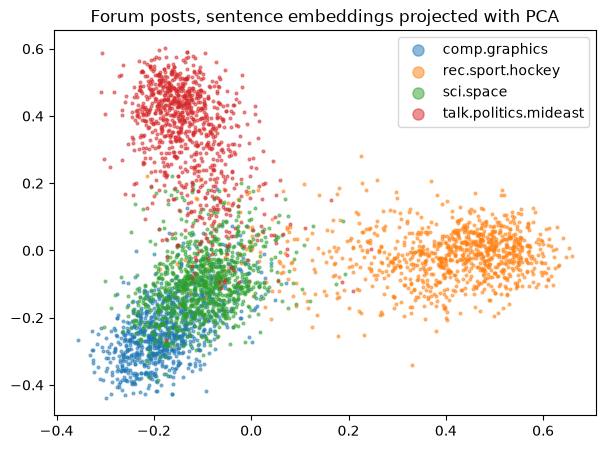

In [29]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
points = pca.fit_transform(post_vectors)
print("Variance kept by two components:", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for topic in categories:
    mask = posts["topic"] == topic
    ax.scatter(points[mask, 0], points[mask, 1], s=4, alpha=0.5, label=topic)
ax.legend(markerscale=4)
ax.set_title("Forum posts, sentence embeddings projected with PCA")
plt.show()

Two components keep only 13% of the variance, and still the forums occupy different regions. Hockey and Middle East politics are well separated, while space and graphics overlap, as they did in Day 1's confusion matrix: both talk about computers, images and software. The guided `[EXTRA]` lab of today goes further with t-SNE, a projection method that preserves neighbourhoods better than PCA.

### A.2 Bigger word vectors and other models

+ `api.load("word2vec-google-news-300")` gives Google's original word2vec vectors: 3 million words and phrases, 300 numbers each, trained on news. It is a 1.6 GB download, so it is not used above. `api.info()["models"].keys()` lists every model `gensim` can download.
+ `SentenceTransformer("all-mpnet-base-v2")` is a larger English model (about 420 MB) that is usually a little better than MiniLM and about five times slower.
+ `SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")` maps more than 50 languages into the same space, so a Spanish query can find an English document.

Any of these replaces the model name in the cells above with no other change.

### A.3 Search with an approximate index

The dot product with every document is exact, and fast enough up to a few hundred thousand documents. Beyond that, libraries build an **approximate nearest neighbour** index that only checks the most promising parts of the space. scikit-learn's `NearestNeighbors` shows the interface (here exact, with the cosine metric):

In [30]:
from sklearn.neighbors import NearestNeighbors

index = NearestNeighbors(n_neighbors=3, metric="cosine").fit(post_vectors)
distances, positions = index.kneighbors(model.encode(["astronauts living on a station in orbit"], normalize_embeddings=True))
print("Positions:", positions[0], "  cosine similarity:", (1 - distances[0]).round(2))

Positions: [ 241  893 3527]   cosine similarity: [0.42 0.41 0.4 ]


The same three posts as `semantic_search` in section 6. Note that `NearestNeighbors` returns cosine **distance**, which is 1 minus the similarity. Chroma, FAISS and pgvector use the same idea: fit an index on the document vectors once, then ask it for the nearest neighbours of each query.